# Real-data classification and stochastic gradients

All 30 Wisconsin Diagnostic features enter a Bayesian logistic model. Preprocessing, MAP geometry and posterior likelihood use training data only; proper held-out scores accompany diagnostic failures.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
ROOT=Path.cwd()
if ROOT.name == "notebooks": ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
torch.set_num_threads(1)
from sampling_lab.targets import load_target
from sampling_lab.artifacts import sha256
def read(path): return json.loads((ROOT/path).read_text())
def numeric(name): return np.load(ROOT/"assets/source_data"/(name+".npz"),allow_pickle=False)
%matplotlib inline


## Independent implementation check

In [2]:
from sampling_lab.posterior import predict
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import log_loss,brier_score_loss
name="logistic_nuts_dispersed_0.1";source=numeric(name);data=load_breast_cancer();idx=source["test_indices"]
output=predict(ROOT/"assets/source_data"/(name+".npz"),data.data[idx],"logistic")
np.testing.assert_allclose(output["probability"],source["probability_test"],rtol=1e-12,atol=1e-12)
print("Test log loss",log_loss(data.target[idx],output["probability"]),"Brier",brier_score_loss(data.target[idx],output["probability"]))
print("Probability is for sklearn class 1 (benign). Credible intervals are for probabilities, not binary outcomes.")

Test log loss 0.06546572266179942 Brier 0.021668457216481436
Probability is for sklearn class 1 (benign). Credible intervals are for probabilities, not binary outcomes.


## Inspect measured evidence

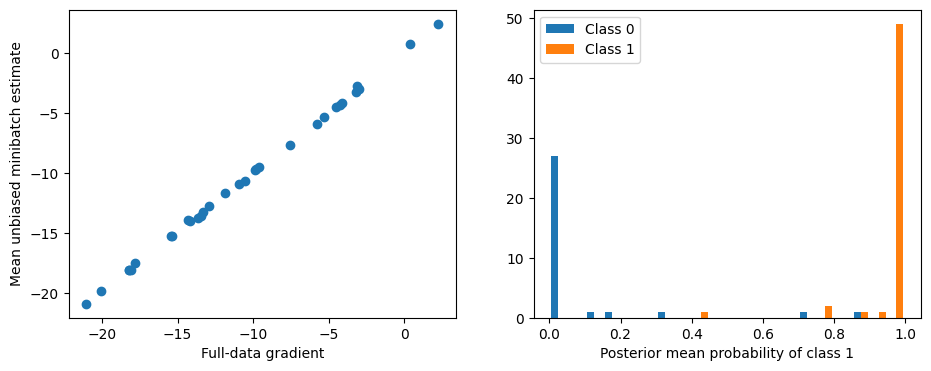

,method,step_size,max_rhat,min_bulk_ess,convergence_flag
40,adaptive_hmc,0.1000,1.008593,959.384901,True
41,adaptive_rwm,0.6000,1.102120,37.814216,False
42,hmc,0.1200,1.008600,1593.139393,True
43,mala,0.0200,1.175176,19.723363,False
44,nuts,0.1000,1.001764,8596.458771,True
45,rwm,0.6000,1.143503,23.016333,False
46,sghmc,0.0005,2.813847,4.651025,False
47,sghmc,0.0020,1.543685,7.134936,False
48,sgld,0.0050,1.734650,6.180901,False
49,sgld,0.0200,1.198335,14.658102,False


In [3]:
target=load_target("logistic");x=target.mean+.2;rng=np.random.default_rng(29)
minibatch=np.mean([target.gradient(x,rng,64) for _ in range(2000)],axis=0)
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].scatter(target.gradient(x),minibatch);axes[0].set(xlabel="Full-data gradient",ylabel="Mean unbiased minibatch estimate")
p=output["probability"];axes[1].hist([p[data.target[idx]==0],p[data.target[idx]==1]],bins=20,label=["Class 0","Class 1"]);axes[1].set(xlabel="Posterior mean probability of class 1");axes[1].legend();plt.show()
rows=pd.read_csv(ROOT/"docs/sampling_comparison.csv");display(rows[rows.target=="logistic"][["method","step_size","max_rhat","min_bulk_ess","convergence_flag"]])

## Interpretation and next step

Read the [theory](../docs/theory.md), [diagnostic scope](../docs/diagnostics.md), and [data protocol](../docs/data_and_protocols.md). Change one declared preset in a separate output directory; keep warmup, test evaluation and model selection distinct. The [interactive explorer](../docs/explorer.html) exposes the complete recorded comparisons.